## Feature Computation

In [1]:
from tqdm import tqdm
from rice import RICES
from dataloader.dataloader import UniqloDataset

In [2]:
dataset = UniqloDataset("./data/uniqlo_processed.csv")

In [3]:
len(dataset)

5094

In [ ]:
# retriever = RICES(dataset, 'cuda', 128)

Precomputing features for RICES: 100%|██████████| 40/40 [13:06<00:00, 19.66s/it]


In [6]:
retriever2 = RICES(dataset, 'cpu', 128, cached_features=cache_features)

In [7]:
def find_relevant_images(item, n=10):
    return retriever2.find([item['image']],n)

In [4]:
# caching the computed features
# took ~ 30 mins to compute
import pickle
cache_location = "./features-cache/uniqlo_vit32.pkl"
# with open(cache_location, 'wb') as f:
#     pickle.dump(retriever.features.cpu(), f)


In [5]:
with open(cache_location, 'rb') as f:
    cache_features = pickle.load(f)

In [8]:
# retriever.features = retriever.features.cpu()

In [8]:
import matplotlib.pyplot as plt

def display_query_and_results(query_image, result_images, n):
    """
    Displays the query image and n result images in a grid.

    Parameters:
    - query_image: numpy array representing the query image.
    - result_images: list of numpy arrays representing the result images.
    - n: integer, number of result images to display.

    """
    # Ensure n is not more than the number of available result images
    n = min(n, len(result_images))
    
    # Set up the figure and axis layout
    fig, axes = plt.subplots(1, n + 1, figsize=(5 * (n + 1), 5))
    
    # Display the query image
    axes[0].imshow(query_image)
    axes[0].set_title("Query Image")
    axes[0].axis("off")
    
    # Display the result images
    for i in range(n):
        axes[i + 1].imshow(result_images[i])
        axes[i + 1].set_title(f"Result {i + 1}")
        axes[i + 1].axis("off")
    
    plt.tight_layout()
    plt.show()


In [9]:
def show_relev_results_api(item, n=10):
    relev_items = find_relevant_images(item, n)
    query_img = item['image']
    res_imgs = [ritem['image'] for ritem in relev_items[0]][::-1][1:]
    display_query_and_results(query_img, res_imgs, 10)

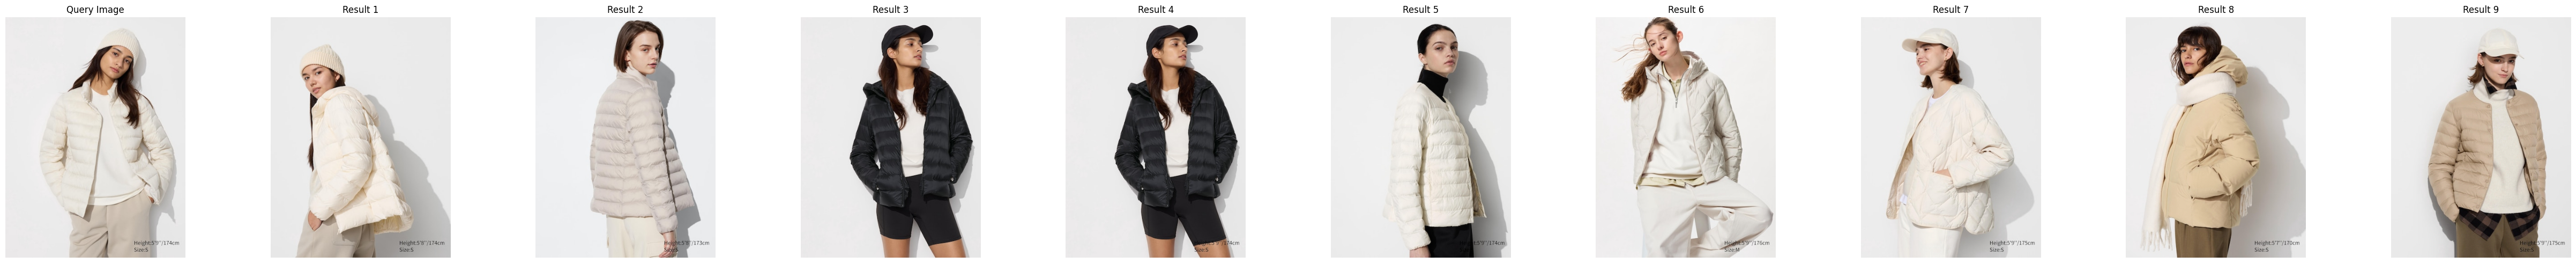

In [11]:
show_relev_results_api(dataset[0], 10)

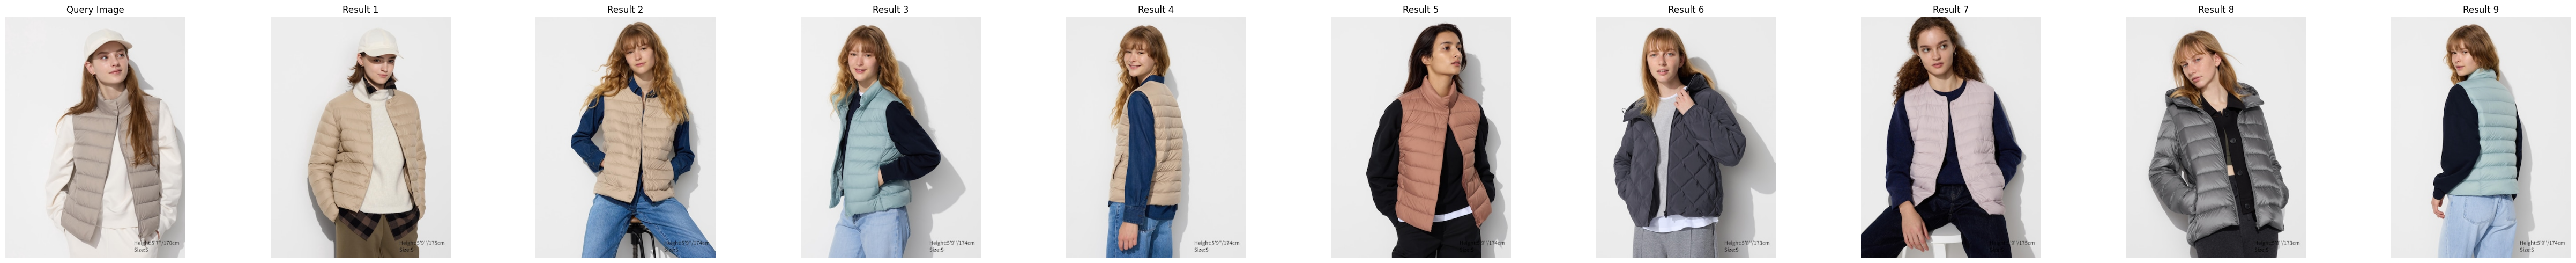

In [10]:
show_relev_results_api(dataset[20], 10)

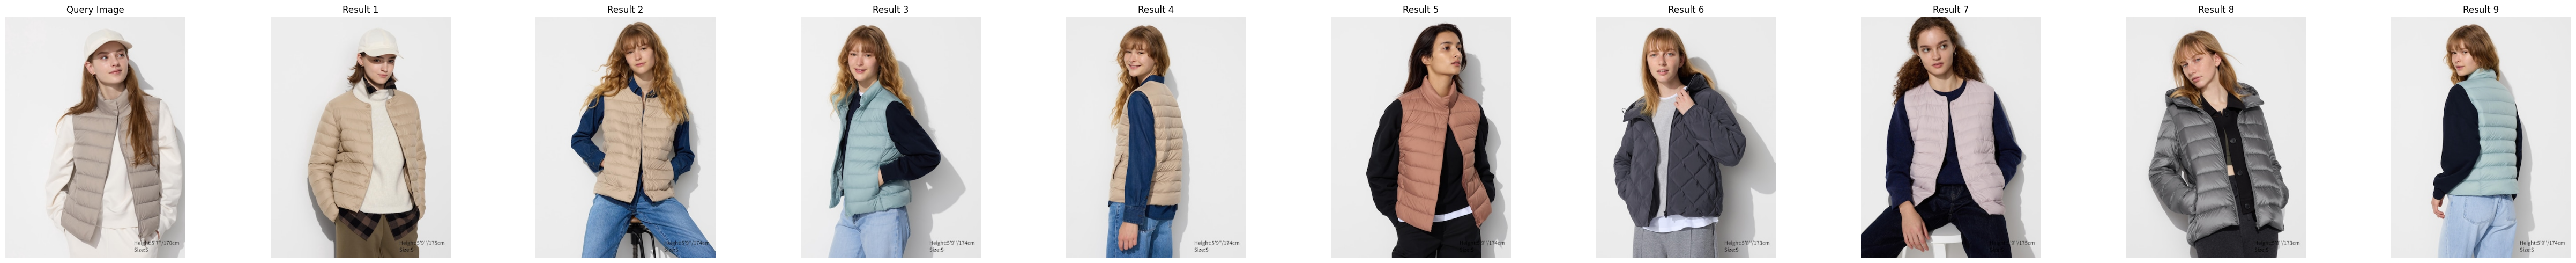

In [15]:
show_relev_results_api(dataset[20], 10)

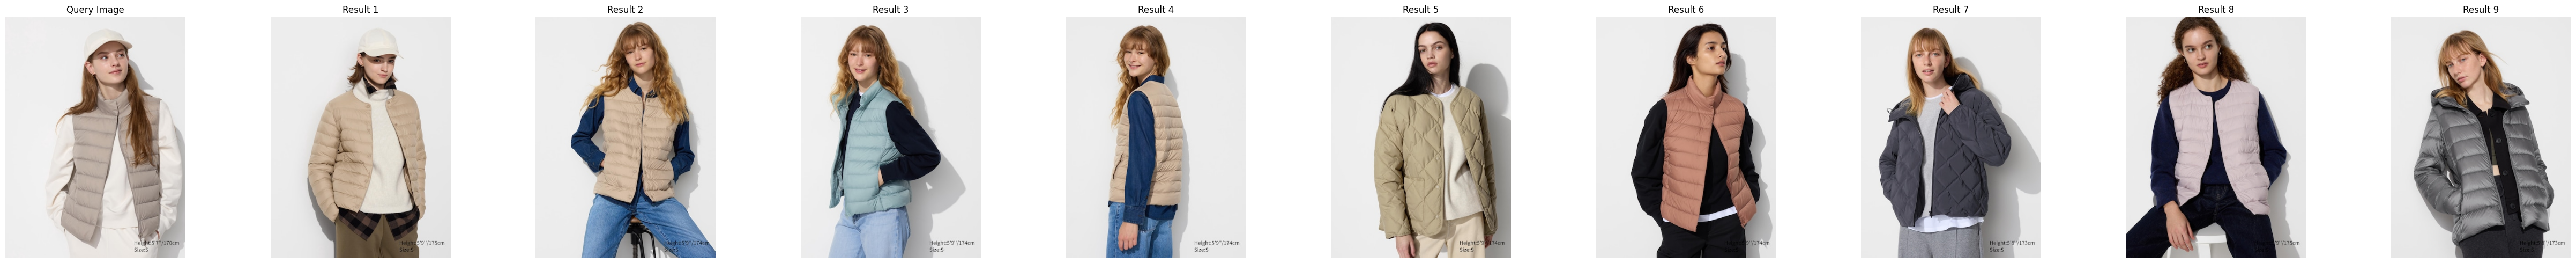

In [ ]:
show_relev_results_api(dataset[20], 10)

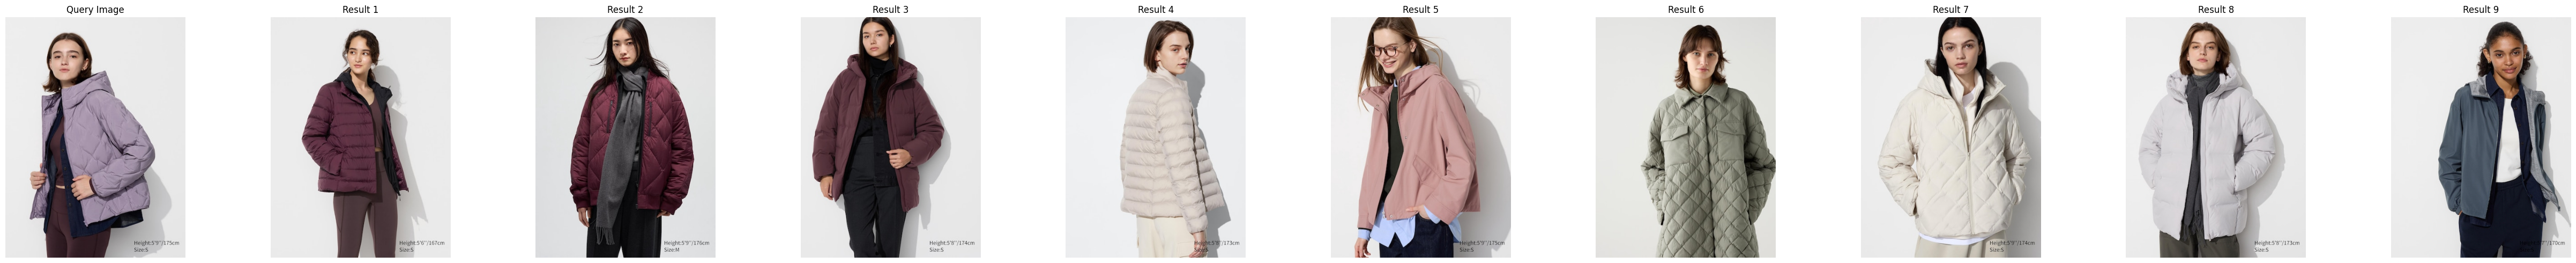

In [41]:
show_relev_results_api(dataset[60], 10)